#**Exploratory Data Analysis**

In [82]:
##Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [83]:
##Load Dataset
data = pd.read_csv("Cleaned_Dataset.csv")
data.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [84]:
##Dataset overview
print("Dataset shape:", data.shape)
print("\nColumn names:")
print(data.columns)
print("\nDataset information:")
data.info()
print("\nFirst five records:")
display(data.head())
print("\nLast five records:")
display(data.tail())

Dataset shape: (1200, 14)

Column names:
Index(['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice',
       'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber',
       'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04



Last five records:


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
1195,ORD201195,2024-06-20,C21126,Desk,1,107.04,392 Main St,Credit Card,Cancelled,TRK38009181,6,FREESHIP,Google,107.04
1196,ORD201196,2024-03-04,C20095,Monitor,2,662.53,778 Main St,Online,Cancelled,TRK69207593,5,NO COUPON,Facebook,1325.06
1197,ORD201197,2023-07-13,C79674,Tablet,2,436.84,275 Main St,Online,Delivered,TRK88039356,2,FREESHIP,Instagram,873.68
1198,ORD201198,2024-08-22,C64753,Chair,4,262.52,509 Main St,Debit Card,Cancelled,TRK71683331,4,WINTER15,Instagram,1050.08
1199,ORD201199,2023-06-11,C57502,Tablet,4,560.58,201 Main St,Gift Card,Returned,TRK51116746,6,SAVE10,Referral,2242.32


In [85]:
##Check data quality
print("Missing values :", data.isnull().sum().sum())

print("\nDuplicate rows:", data.duplicated().sum())
print("\nDuplicate OrderIDs:", data["OrderID"].duplicated().sum())

Missing values : 0

Duplicate rows: 0

Duplicate OrderIDs: 0


In [86]:
##Convert Date to datetime
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month
data["Day"] = data["Date"].dt.day

display(data[["Date", "Year", "Month", "Day"]].head())

,Date,Year,Month,Day
0,2023-01-04,2023,1,4
1,2024-08-23,2024,8,23
2,2024-02-27,2024,2,27
3,2023-10-15,2023,10,15
4,2025-05-08,2025,5,8


In [87]:
##Descriptive Statistics
analysis_columns = [
    "Quantity",
    "UnitPrice",
    "ItemsInCart",
    "TotalPrice"
]
numeric_data = data[analysis_columns]
descriptive_stats = numeric_data.describe().T
descriptive_stats["Count"] = numeric_data.count()
descriptive_stats["Mean"] = numeric_data.mean()
descriptive_stats["Median"] = numeric_data.median()
display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max,Count,Mean,Median
Quantity,1200.0,2.945833,1.407557,1.00,2.0000,3.000,4.000,5.00,1200,2.945833,3.000
UnitPrice,1200.0,356.412750,197.177146,11.39,186.0625,364.210,521.570,699.93,1200,356.412750,364.210
ItemsInCart,1200.0,5.485000,2.281983,1.00,4.0000,5.000,7.000,10.00,1200,5.485000,5.000
TotalPrice,1200.0,1053.968300,819.856558,11.39,410.5200,823.615,1578.475,3456.40,1200,1053.968300,823.615


In [88]:
##Categorical Analysis
categorical_columns = [
    "Product", "PaymentMethod", "OrderStatus",
    "ReferralSource", "CouponCode"
]
for column in categorical_columns:
    if column in data.columns:
        print(f"\n{column} analysis")
        counts = data[column].value_counts(dropna=False)
        percentages = data[column].value_counts(normalize=True, dropna=False) * 100
        result = pd.DataFrame({
            "Count": counts,
            "Percentage": percentages
        })
        display(result)


Product analysis


,Count,Percentage
Product,,
Printer,181,15.083333
Tablet,179,14.916667
Chair,178,14.833333
Laptop,173,14.416667
Desk,170,14.166667
Monitor,163,13.583333
Phone,156,13.000000



PaymentMethod analysis


,Count,Percentage
PaymentMethod,,
Online,258,21.500000
Cash,246,20.500000
Credit Card,234,19.500000
Debit Card,232,19.333333
Gift Card,230,19.166667



OrderStatus analysis


,Count,Percentage
OrderStatus,,
Cancelled,250,20.833333
Returned,247,20.583333
Pending,237,19.750000
Shipped,235,19.583333
Delivered,231,19.250000



ReferralSource analysis


,Count,Percentage
ReferralSource,,
Instagram,259,21.583333
Email,250,20.833333
Google,241,20.083333
Facebook,228,19.000000
Referral,222,18.500000



CouponCode analysis


,Count,Percentage
CouponCode,,
FREESHIP,313,26.083333
NO COUPON,309,25.750000
WINTER15,292,24.333333
SAVE10,286,23.833333


In [89]:
##Product Analysis
product_analysis = data.groupby("Product").agg(
    Total_Orders=("OrderID", "count"),
    Total_Quantity=("Quantity", "sum"),
    Average_Unit_Price=("UnitPrice", "mean"),
    Recorded_Order_Value=("TotalPrice", "sum")
).sort_values("Total_Orders", ascending=False)

display(product_analysis)

,Total_Orders,Total_Quantity,Average_Unit_Price,Recorded_Order_Value
Product,,,,
Printer,181,542,351.714917,195612.61
Tablet,179,497,367.679106,186568.95
Chair,178,562,355.660281,195620.11
Laptop,173,535,357.707052,192126.56
Desk,170,508,329.608118,167459.93
Monitor,163,480,358.663620,175651.41
Phone,156,411,375.217564,151722.39


In [90]:
##Monthly Trend Analysis
monthly_trend = (
    data.dropna(subset=["Date"])
      .set_index("Date")["TotalPrice"]
      .resample("MS")
      .sum()
)
display(monthly_trend.to_frame("Recorded_Order_Value"))

,Recorded_Order_Value
Date,
2023-01-01,56685.75
2023-02-01,40117.66
2023-03-01,48609.37
2023-04-01,27751.71
2023-05-01,63836.84
2023-06-01,49500.19
2023-07-01,42820.66
2023-08-01,54352.14
2023-09-01,29526.67


In [91]:
##Yearly Trend Analysis
yearly_trend = data.groupby("Year").agg(
    Total_Orders=("OrderID", "count"),
    Total_Quantity=("Quantity", "sum"),
    Recorded_Order_Value=("TotalPrice", "sum")
)
display(yearly_trend)

,Total_Orders,Total_Quantity,Recorded_Order_Value
Year,,,
2023,510,1524,552643.24
2024,459,1351,480235.87
2025,231,660,231882.85


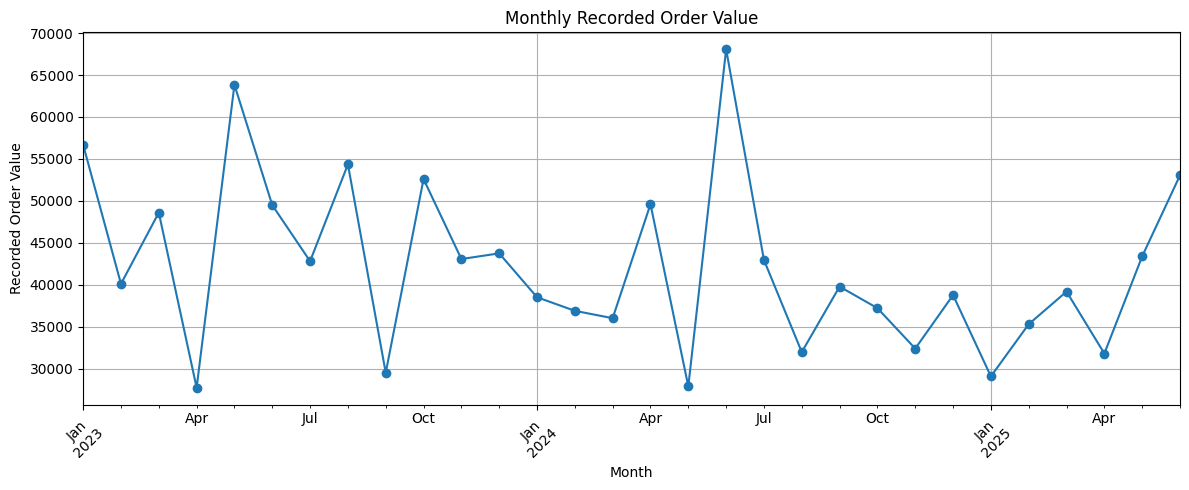

In [92]:
##Monthly trend chart
plt.figure(figsize=(12, 5))
monthly_trend.plot(marker="o")
plt.title("Monthly Recorded Order Value")
plt.xlabel("Month")
plt.ylabel("Recorded Order Value")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

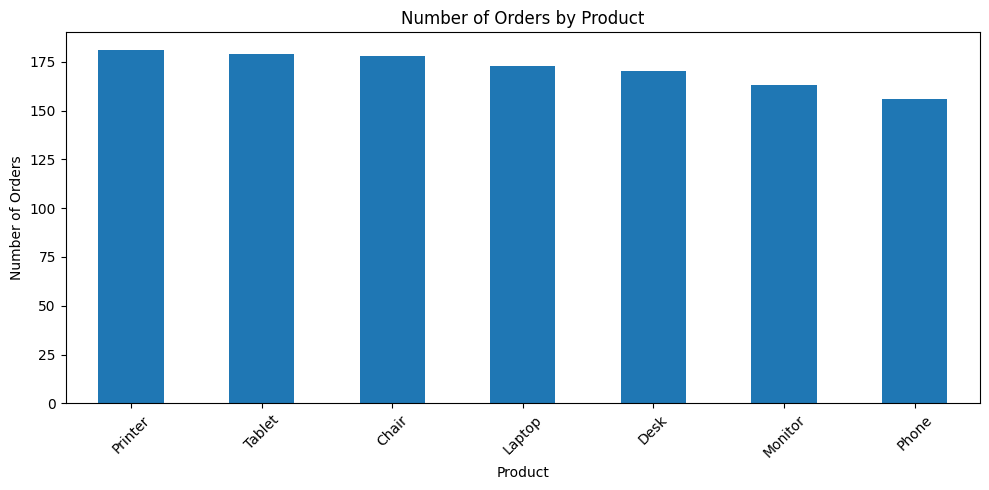

In [93]:
##Orders by product
product_counts = data["Product"].value_counts()
plt.figure(figsize=(10, 5))
product_counts.plot(kind="bar")
plt.title("Number of Orders by Product")
plt.xlabel("Product")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

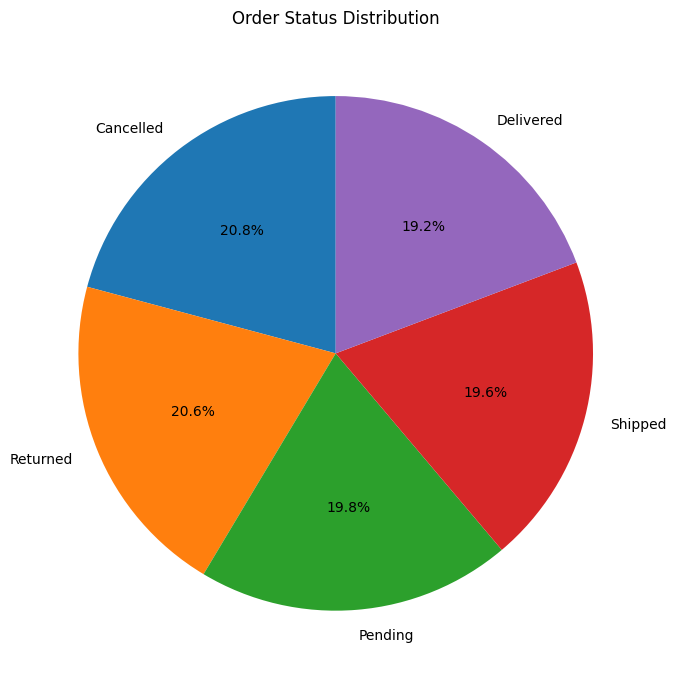

In [94]:
##Order status distribution
status_counts = data["OrderStatus"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(status_counts, labels=status_counts.index,
        autopct="%1.1f%%", startangle=90)
plt.title("Order Status Distribution")
plt.tight_layout()
plt.show()

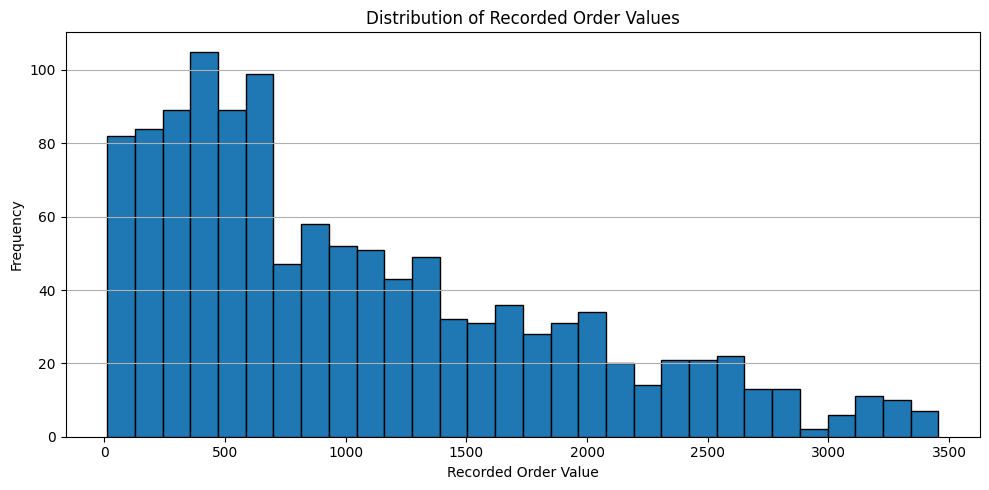

In [95]:
##Distribution of recorded order values
plt.figure(figsize=(10, 5))
plt.hist(data["TotalPrice"].dropna(), bins=30, edgecolor="black")
plt.title("Distribution of Recorded Order Values")
plt.xlabel("Recorded Order Value")
plt.ylabel("Frequency")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [96]:
##Outlier Detection using IQR Method
numeric_columns = data.select_dtypes(include=np.number).columns
outlier_rows = []

for column in numeric_columns:
    values = data[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((values < lower_bound) | (values > upper_bound)).sum()

    outlier_rows.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,Quantity,2.0000,4.000,2.0000,-1.00000,7.00000,0
1,UnitPrice,186.0625,521.570,335.5075,-317.19875,1024.83125,0
2,ItemsInCart,4.0000,7.000,3.0000,-0.50000,11.50000,0
3,TotalPrice,410.5200,1578.475,1167.9550,-1341.41250,3330.40750,8
4,Year,2023.0000,2024.000,1.0000,2021.50000,2025.50000,0
5,Month,3.0000,9.000,6.0000,-6.00000,18.00000,0
6,Day,8.0000,24.000,16.0000,-16.00000,48.00000,0


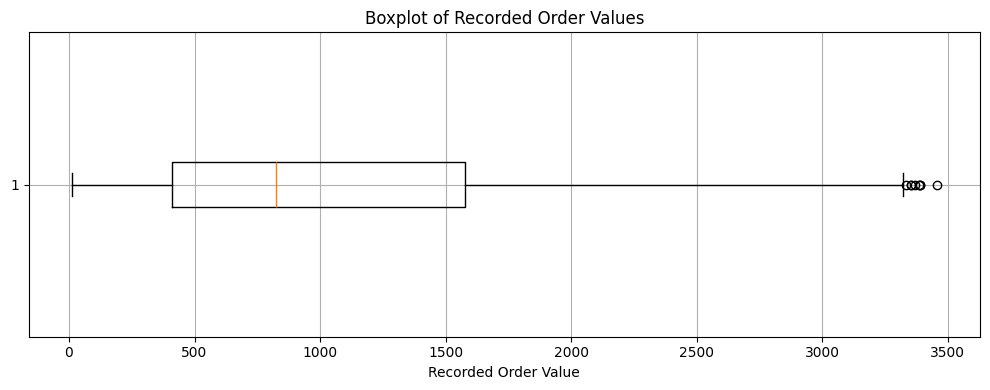

In [97]:
##Boxplot for TotalPrice
plt.figure(figsize=(10, 4))
plt.boxplot(data["TotalPrice"].dropna(), vert=False)
plt.title("Boxplot of Recorded Order Values")
plt.xlabel("Recorded Order Value")
plt.grid(True)
plt.tight_layout()
plt.show()

In [98]:
##Correlation matrix
correlation = data.select_dtypes(include=np.number).corr()
display(correlation)

,Quantity,UnitPrice,ItemsInCart,TotalPrice,Year,Month,Day
Quantity,1.000000,0.014553,0.650061,0.615251,-0.033229,-0.015118,0.017379
UnitPrice,0.014553,1.000000,0.000602,0.717081,-0.002233,-0.026130,0.042203
ItemsInCart,0.650061,0.000602,1.000000,0.392540,-0.050464,-0.018151,-0.031994
TotalPrice,0.615251,0.717081,0.392540,1.000000,-0.036174,-0.027734,0.040718
Year,-0.033229,-0.002233,-0.050464,-0.036174,1.000000,-0.269465,-0.016934
Month,-0.015118,-0.026130,-0.018151,-0.027734,-0.269465,1.000000,0.022109
Day,0.017379,0.042203,-0.031994,0.040718,-0.016934,0.022109,1.000000


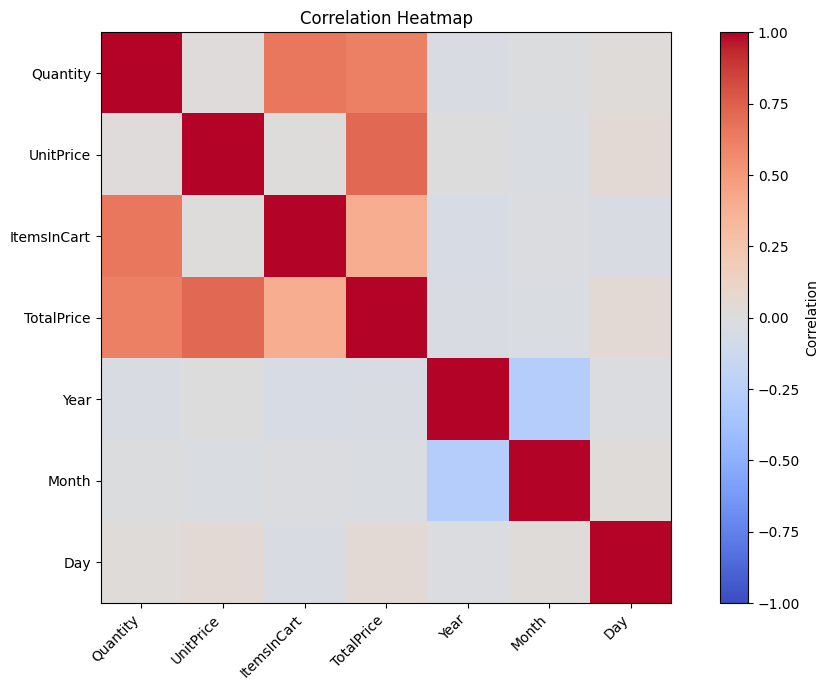

In [99]:
##Correlation heatmap
plt.figure(figsize=(10, 7))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns,
           rotation=45, ha="right")
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [100]:
##Basic findings
print("************  KEY OBSERVATIONS  ************\n")

if "OrderID" in data.columns:
    print("Number of unique orders:", data["OrderID"].nunique())
if "Product" in data.columns:
    print("Most frequently ordered product:", data["Product"].value_counts().idxmax())
if "OrderStatus" in data.columns:
    print("Most common order status:", data["OrderStatus"].value_counts().idxmax())
if "ReferralSource" in data.columns:
    print("Most common referral source:", data["ReferralSource"].value_counts().idxmax())

print("Average recorded order value:", round(data["TotalPrice"].mean(), 2))
print("Highest recorded order value:", round(data["TotalPrice"].max(), 2))
print("Lowest recorded order value:", round(data["TotalPrice"].min(), 2))

if not monthly_trend.empty:
    print("Month with highest recorded order value:",
          monthly_trend.idxmax().strftime("%B %Y"))
    print("Highest monthly recorded order value:", round(monthly_trend.max(), 2))

************  KEY OBSERVATIONS  ************

Number of unique orders: 1200
Most frequently ordered product: Printer
Most common order status: Cancelled
Most common referral source: Instagram
Average recorded order value: 1053.97
Highest recorded order value: 3456.4
Lowest recorded order value: 11.39
Month with highest recorded order value: June 2024
Highest monthly recorded order value: 68068.54


In [101]:
##Export analysis tables to a separate Excel workbook
output_file = "EDA_Analysis_Report.xlsx"

with pd.ExcelWriter(output_file) as writer:
    descriptive_stats.to_excel(writer, sheet_name="Basic Statistics")
    product_analysis.to_excel(writer, sheet_name="Product Analysis")
    monthly_trend.to_frame("Recorded_Order_Value").to_excel(writer, sheet_name="Monthly Trends")
    yearly_trend.to_excel(writer, sheet_name="Yearly Trends")
    outlier_summary.to_excel(writer, sheet_name="Outlier Analysis", index=False)
    correlation.to_excel(writer, sheet_name="Correlation")

print(f"Analysis report saved as: {output_file}")

Analysis report saved as: EDA_Analysis_Report.xlsx


## Conclusion

In this project, I performed Exploratory Data Analysis (EDA) on a cleaned dataset containing 1,200 records and 14 columns. I used Python libraries such as Pandas, NumPy and Matplotlib to explore the data, calculate descriptive statistics, analyze categories, and identify monthly and yearly trends.

The analysis showed that Printer was the most frequently ordered product, while June 2024 recorded the highest monthly order value. Using the IQR method, I identified 8 outliers in the TotalPrice column. I also explored relationships between numerical variables through correlation analysis and visualized the findings using different charts.

Overall, this project helped me understand the dataset more deeply and identify meaningful patterns, unusual values, and business-related insights that can support data driven decision making.